# Thematic Clustering of GDPR Projects

We have 31 EU-funded GDPR projects with textual descriptions, domains, and keywords. The goal here is to see if these projects naturally group into thematic clusters, and whether those clusters correlate with funding levels.

We try two approaches:
1. **TF-IDF** — classical bag-of-words, fast and interpretable but misses semantic similarity (e.g., "privacy-preserving" and "data protection" look unrelated)
2. **Sentence embeddings (all-mpnet-base-v2)** — captures meaning, so semantically similar descriptions land close together even if they use different words

Both feed into hierarchical clustering (Ward linkage), which works well for small datasets like ours (n=31). We compare the two to see if they agree.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 150

In [16]:
df = pd.read_csv('gdpr_projects.csv')
df['start_date'] = pd.to_datetime(df['start_date'])
df['end_date'] = pd.to_datetime(df['end_date'])
df['duration_months'] = ((df['end_date'] - df['start_date']).dt.days / 30.44).round(0).astype(int)
df['start_year'] = df['start_date'].dt.year
print(f'{len(df)} projects loaded')
df[['project_name', 'description', 'funding_eur']].head()

31 projects loaded


,project_name,description,funding_eur
0,smashHit,Smart Sharing of Health and Industry Data via ...,4500000.0
1,Odlaw,Retroactive Data Protection Compliance Tool fo...,NaN
2,RuleKeeper,GDPR-Aware Personal Data Compliance for Web Fr...,NaN
3,PDP4E,Privacy and Data Protection Tools for Engineer...,4200000.0
4,SPECIAL,Scalable Policy-aware Linked Data Architecture...,4400000.0


## Approach A: TF-IDF

### A1. Vectorization

We combine description, keywords, and domain into a single text field per project so the vectorizer has more to work with. Using unigrams and bigrams, capped at 100 features, and requiring each term to appear in at least 2 projects (min_df=2) to filter out noise.

In [17]:
df['text'] = (
    df['description'].fillna('') + ' ' +
    df['keywords'].fillna('') + ' ' +
    df['domain'].fillna('')
)

tfidf = TfidfVectorizer(
    max_features=100,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=2
)
X = tfidf.fit_transform(df['text'])
print(f'TF-IDF matrix: {X.shape}')
print(f'Top terms: {tfidf.get_feature_names_out()[:20]}')

TF-IDF matrix: (31, 100)
Top terms: ['analytics' 'analytics data' 'assessment' 'aware' 'awareness'
 'awareness gdpr' 'based' 'blockchain' 'border' 'business'
 'business compliance' 'cities' 'compliance' 'compliance healthcare'
 'compliance smes' 'compliance tool' 'compliance web' 'compliant' 'cross'
 'cross border']


### A2. Hierarchical Clustering (Dendrogram)

With only 31 projects, hierarchical clustering is a better fit than K-Means — we can look at the full dendrogram and see where natural groupings form. Ward linkage minimizes within-cluster variance, which tends to produce compact, evenly-sized clusters.

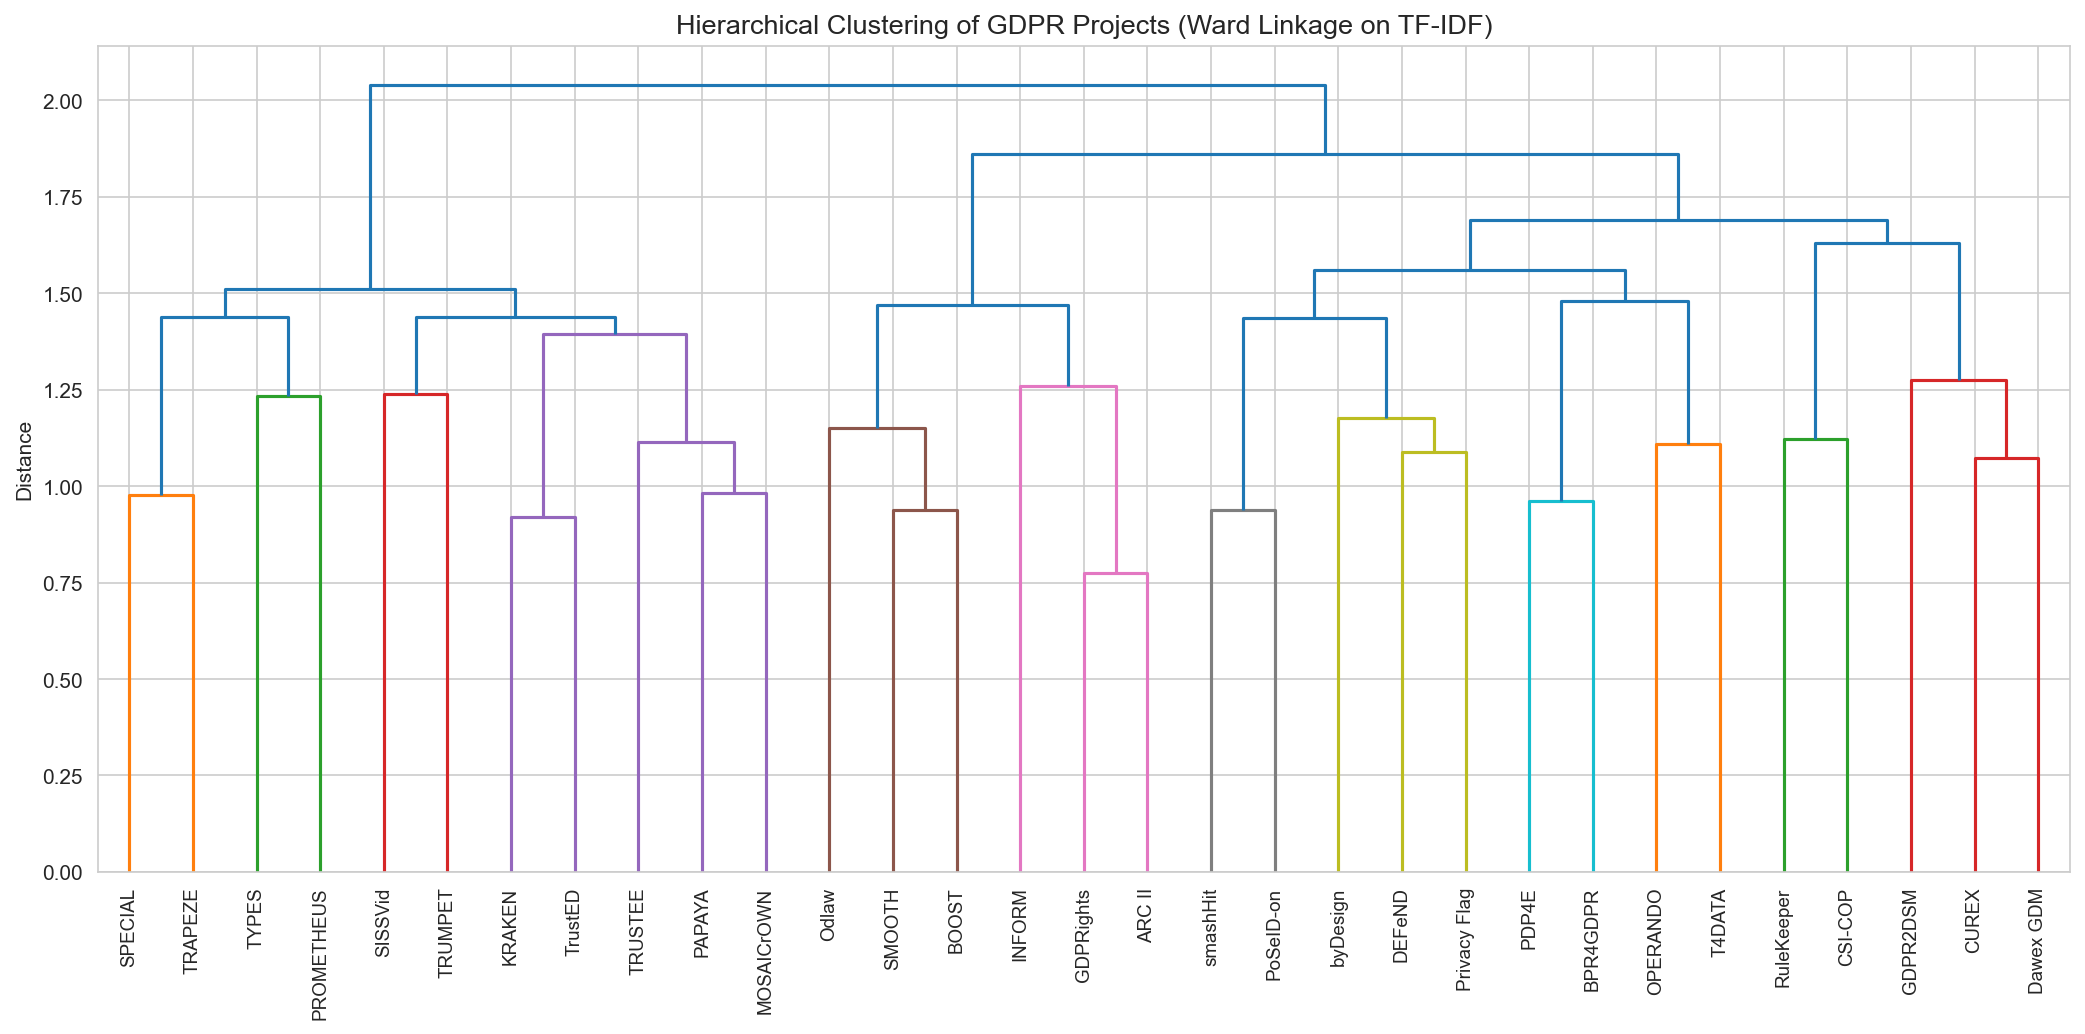

In [18]:
Z = linkage(X.toarray(), method='ward', metric='euclidean')

fig, ax = plt.subplots(figsize=(14, 7))
dendrogram(
    Z,
    labels=df['project_name'].values,
    leaf_rotation=90,
    leaf_font_size=9,
    ax=ax
)
ax.set_title('Hierarchical Clustering of GDPR Projects (Ward Linkage on TF-IDF)', fontsize=13)
ax.set_ylabel('Distance')
plt.tight_layout()
plt.savefig('dendrogram.png', bbox_inches='tight')
plt.show()

### A3. Picking the right number of clusters

Rather than eyeballing the dendrogram cut, we sweep k from 2 to 7 and check the silhouette score for each. Higher silhouette means tighter, more separated clusters. This isn't perfect for small n, but it gives us a defensible starting point.

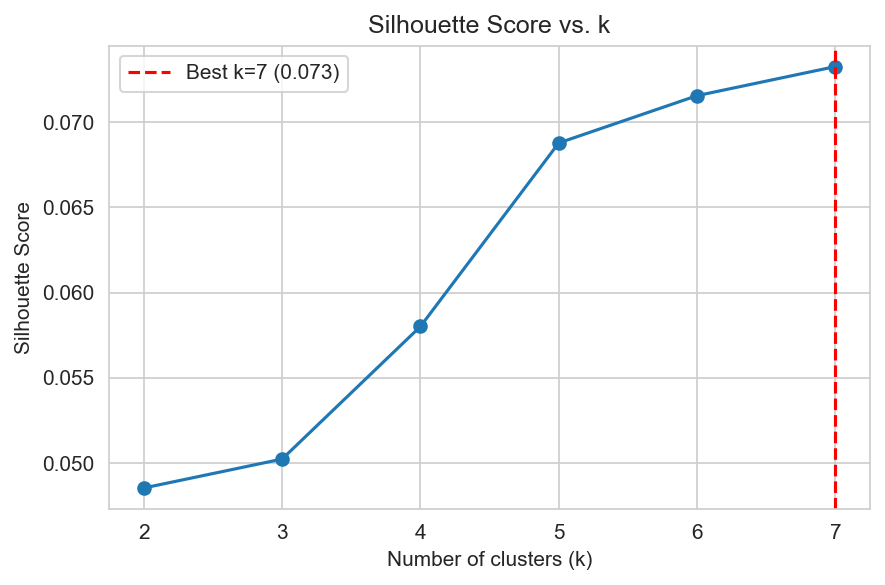

Best k = 7, silhouette = 0.073


In [19]:
X_dense = X.toarray()
sil_scores = {}
for k in range(2, 8):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_dense)
    sil_scores[k] = silhouette_score(X_dense, labels)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(list(sil_scores.keys()), list(sil_scores.values()), 'o-')
ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Silhouette Score')
ax.set_title('Silhouette Score vs. k')
best_k = max(sil_scores, key=sil_scores.get)
ax.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k} ({sil_scores[best_k]:.3f})')
ax.legend()
plt.tight_layout()
plt.savefig('silhouette_scores.png', bbox_inches='tight')
plt.show()
print(f'Best k = {best_k}, silhouette = {sil_scores[best_k]:.3f}')

### A4. Cluster visualization (PCA)

PCA down to 2 dimensions so we can actually see the clusters. Bubble size is proportional to funding — if bigger projects cluster together, that's interesting. Projects with missing funding get the median value for sizing only.

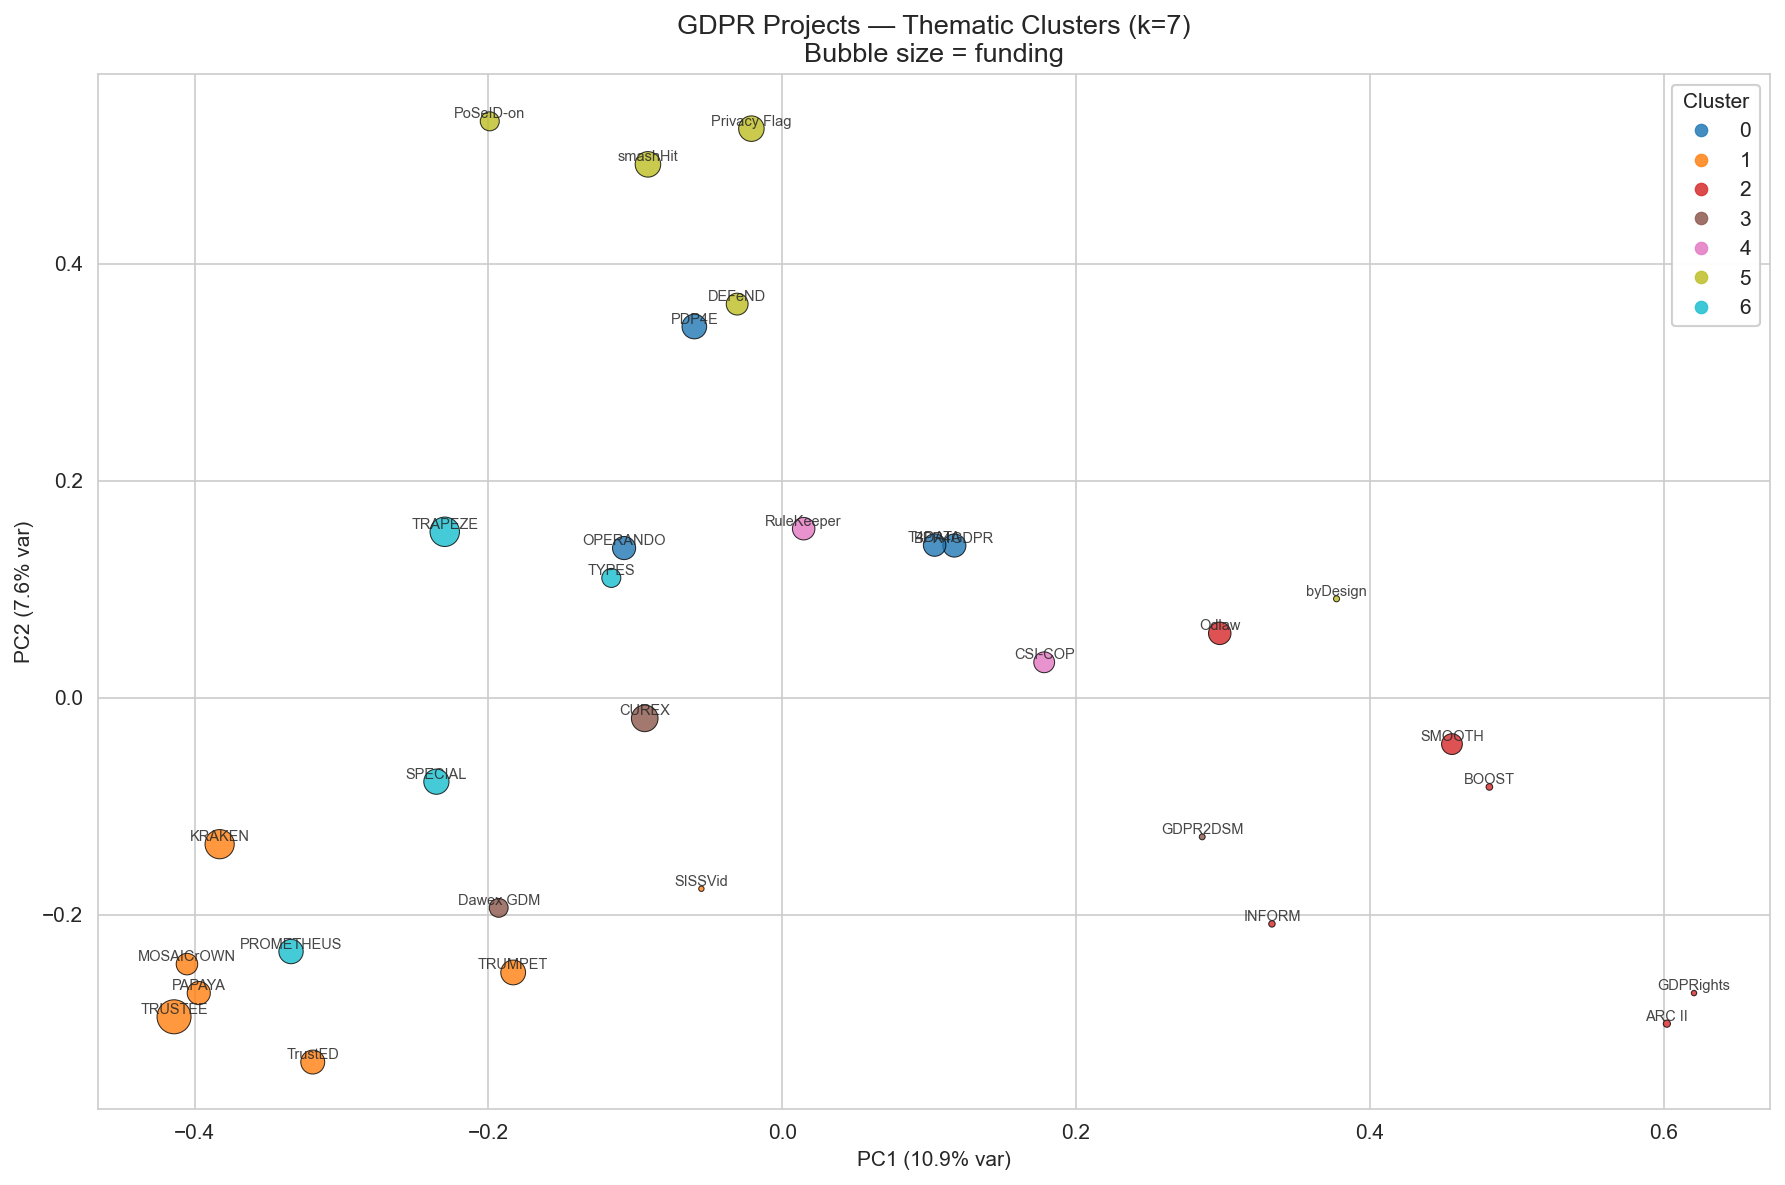

In [20]:
df['cluster'] = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X_dense)
pca = PCA(n_components=2)
coords = pca.fit_transform(X_dense)
df['pca_x'] = coords[:, 0]
df['pca_y'] = coords[:, 1]

fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(
    df['pca_x'], df['pca_y'],
    c=df['cluster'],
    s=df['funding_eur'].fillna(df['funding_eur'].median()) / 30000,
    cmap='tab10',
    alpha=0.8,
    edgecolors='black',
    linewidth=0.5
)
for _, row in df.iterrows():
    ax.annotate(row['project_name'], (row['pca_x'], row['pca_y']),
                fontsize=7, ha='center', va='bottom', alpha=0.85)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} var)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} var)')
ax.set_title(f'GDPR Projects — Thematic Clusters (k={best_k})\nBubble size = funding', fontsize=13)
legend1 = ax.legend(*scatter.legend_elements(), title='Cluster', loc='upper right')
ax.add_artist(legend1)
plt.tight_layout()
plt.savefig('thematic_clusters_pca.png', bbox_inches='tight')
plt.show()

### A5. What's in each cluster?

For each cluster we pull out the top TF-IDF terms (what words characterize it) and the funding stats. This tells us whether the clusters are thematically coherent and whether funding differs meaningfully across them.

In [21]:
feature_names = tfidf.get_feature_names_out()

for c in sorted(df['cluster'].unique()):
    mask = (df['cluster'] == c).values  # numpy array for sparse indexing
    cluster_projects = df.loc[mask, 'project_name'].tolist()
    cluster_funding = df.loc[mask, 'funding_eur'].dropna()
    
    # Top TF-IDF terms for this cluster
    cluster_tfidf_mean = X[mask].toarray().mean(axis=0)
    top_idx = cluster_tfidf_mean.argsort()[-8:][::-1]
    top_terms = [feature_names[i] for i in top_idx]
    
    print(f'\n=== Cluster {c} ({mask.sum()} projects) ===')
    print(f'Projects: {", ".join(cluster_projects)}')
    print(f'Top terms: {", ".join(top_terms)}')
    if len(cluster_funding) > 0:
        print(f'Funding — mean: €{cluster_funding.mean():,.0f}, '
              f'median: €{cluster_funding.median():,.0f}, '
              f'range: €{cluster_funding.min():,.0f}–€{cluster_funding.max():,.0f}')
    else:
        print('Funding — no data')


=== Cluster 0 (4 projects) ===
Projects: PDP4E, BPR4GDPR, OPERANDO, T4DATA
Top terms: engineering, public, privacy, data protection, protection, healthcare, compliance healthcare, business
Funding — mean: €3,866,667, median: €3,700,000, range: €3,700,000–€4,200,000

=== Cluster 1 (7 projects) ===
Projects: TRUSTEE, PAPAYA, MOSAICrOWN, KRAKEN, SISSVid, TRUMPET, TrustED
Top terms: data, privacy, encryption, privacy preserving, preserving, analytics, healthcare, data sharing
Funding — mean: €4,171,864, median: €3,960,000, range: €199,700–€8,000,000

=== Cluster 2 (6 projects) ===
Projects: Odlaw, INFORM, SMOOTH, BOOST, GDPRights, ARC II
Top terms: compliance, smes, awareness, gdpr, tool, training, gdpr compliance, gdpr awareness
Funding — mean: €829,702, median: €305,410, range: €202,600–€2,990,000

=== Cluster 3 (3 projects) ===
Projects: CUREX, Dawex GDM, GDPR2DSM
Top terms: data, data exchange, exchange, single market, market, digital single, single, digital
Funding — mean: €2,533,667

### A6. Funding distribution per cluster

A boxplot to see if certain thematic areas attract more funding than others. The strip plot overlay shows individual projects so we can spot outliers.

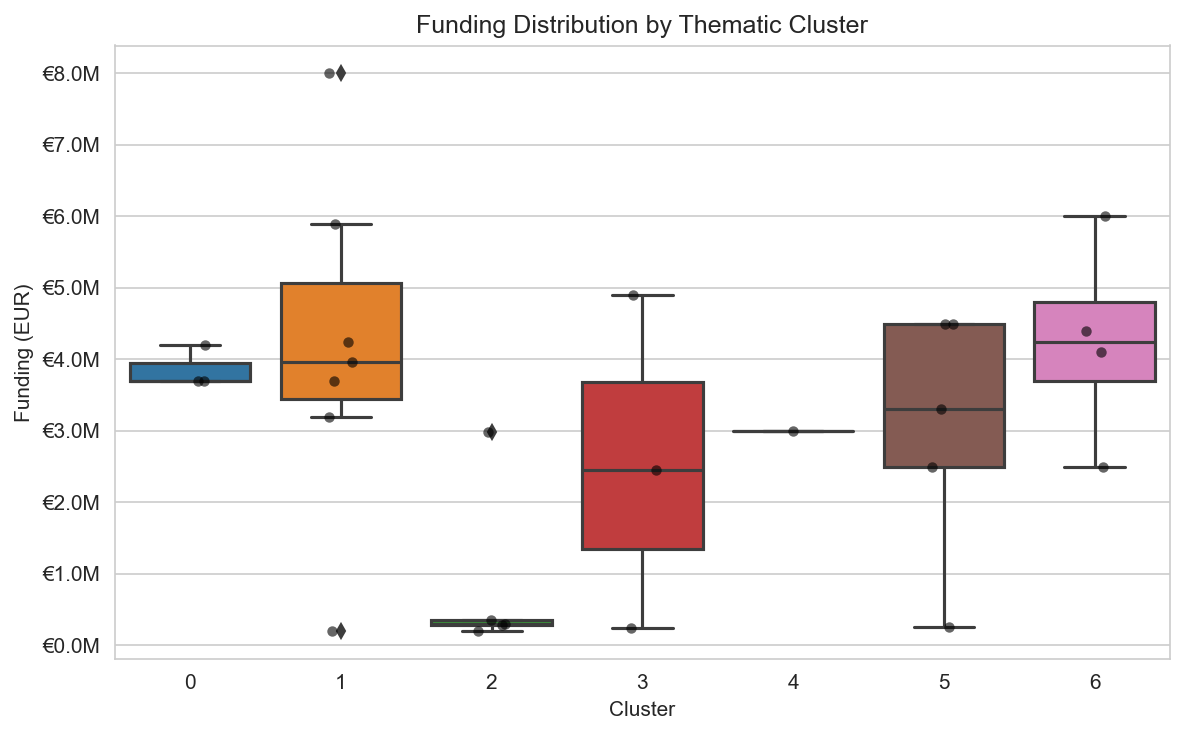

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
df_funded = df.dropna(subset=['funding_eur'])
sns.boxplot(data=df_funded, x='cluster', y='funding_eur', ax=ax, palette='tab10')
sns.stripplot(data=df_funded, x='cluster', y='funding_eur', ax=ax, color='black', size=5, alpha=0.6)
ax.set_ylabel('Funding (EUR)')
ax.set_xlabel('Cluster')
ax.set_title('Funding Distribution by Thematic Cluster')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'€{x/1e6:.1f}M'))
plt.tight_layout()
plt.savefig('cluster_funding_boxplot.png', bbox_inches='tight')
plt.show()

## Approach B: Sentence Embeddings (all-mpnet-base-v2)

TF-IDF only matches on exact words and bigrams. Two projects could be doing very similar things but use completely different terminology, and TF-IDF would miss that. Sentence transformers like mpnet encode the *meaning* of a sentence into a 768-dimensional vector, so "privacy-preserving data analytics" and "encrypted computation for personal data" end up close together.

We run the same clustering pipeline on mpnet embeddings and then compare with TF-IDF to see where they agree and disagree.

In [23]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('all-mpnet-base-v2')
X_mpnet = model.encode(df['text'].tolist(), show_progress_bar=True)
print(f'Embedding matrix: {X_mpnet.shape}')

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding matrix: (31, 768)


### B1. Dendrogram on mpnet embeddings

Same Ward linkage as before, just on the 768-d embeddings instead of TF-IDF features. The tree structure might look quite different since mpnet captures semantic relationships that word-overlap methods miss.

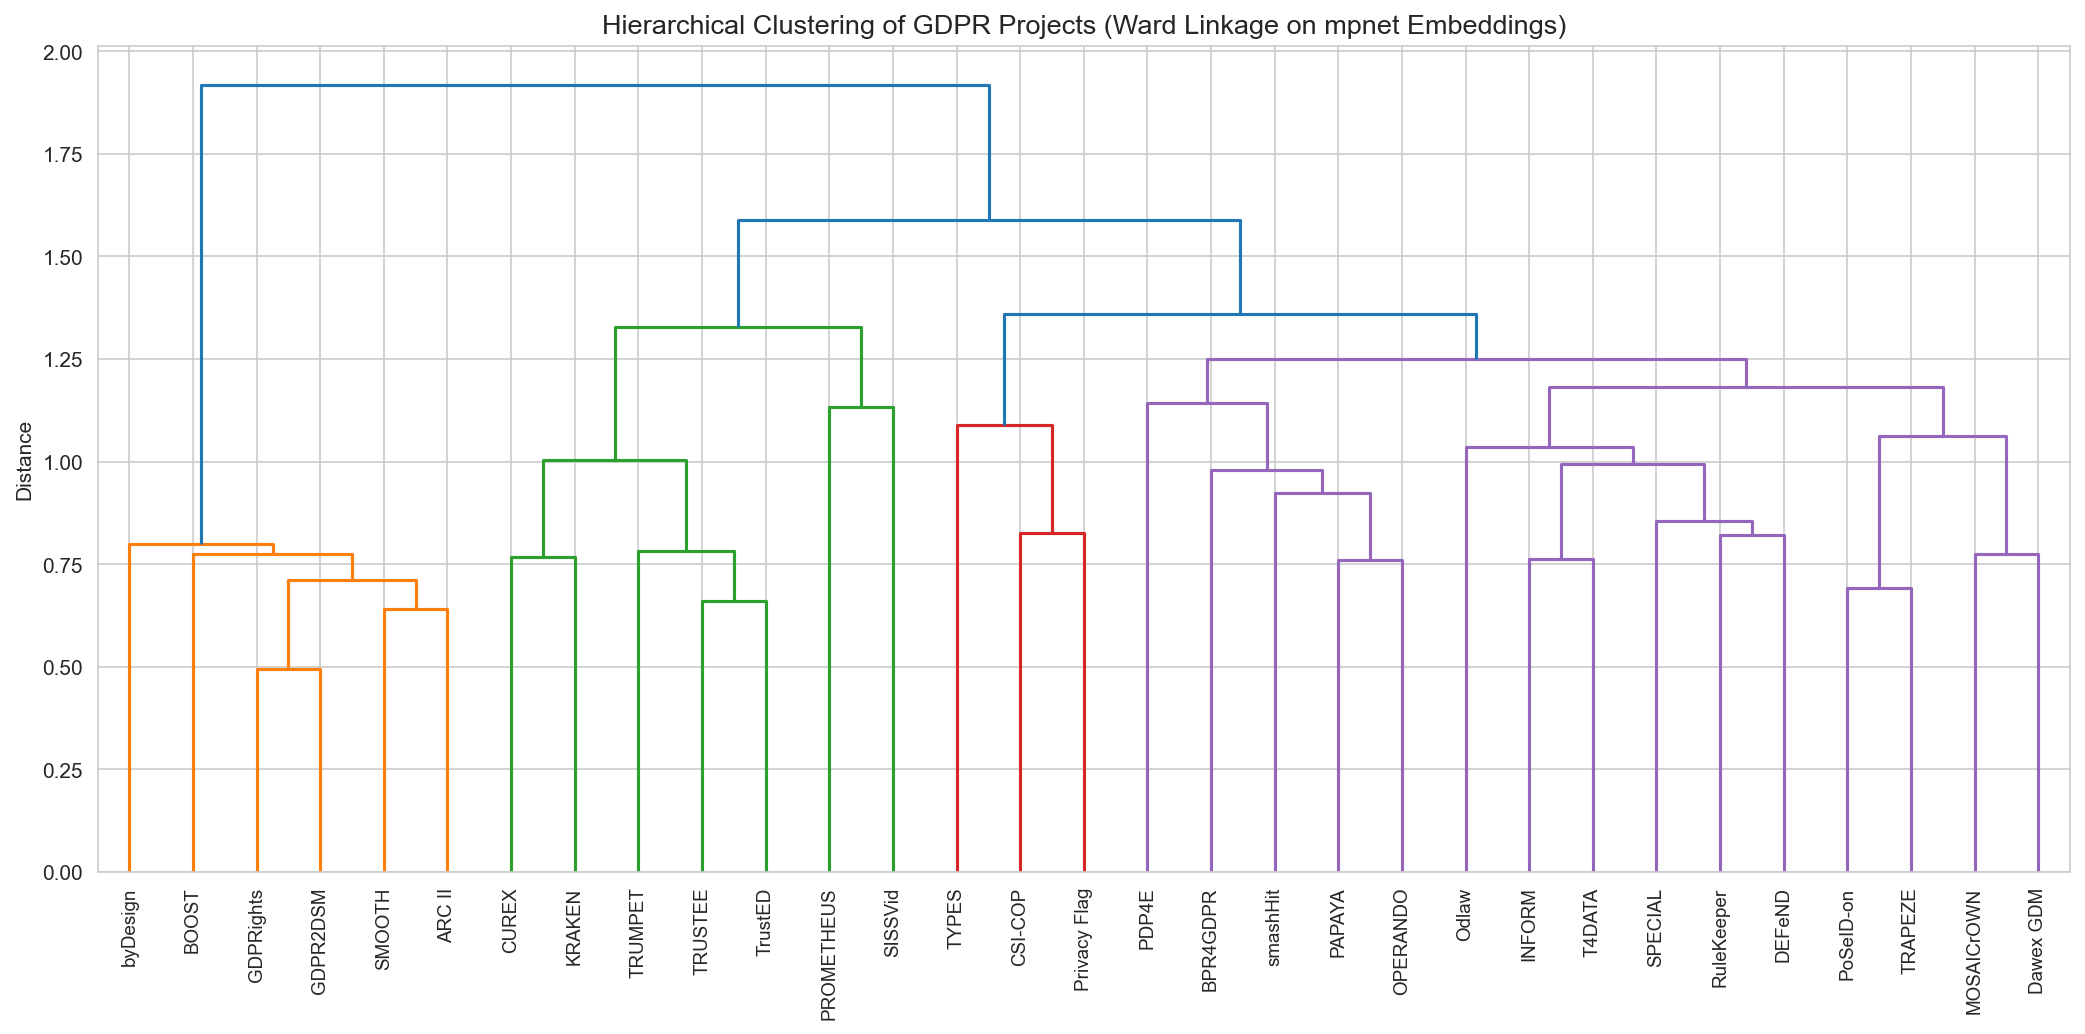

In [24]:
Z_mpnet = linkage(X_mpnet, method='ward', metric='euclidean')

fig, ax = plt.subplots(figsize=(14, 7))
dendrogram(
    Z_mpnet,
    labels=df['project_name'].values,
    leaf_rotation=90,
    leaf_font_size=9,
    ax=ax
)
ax.set_title('Hierarchical Clustering of GDPR Projects (Ward Linkage on mpnet Embeddings)', fontsize=13)
ax.set_ylabel('Distance')
plt.tight_layout()
plt.savefig('dendrogram_mpnet.png', bbox_inches='tight')
plt.show()

### B2. Silhouette scores and cluster assignment

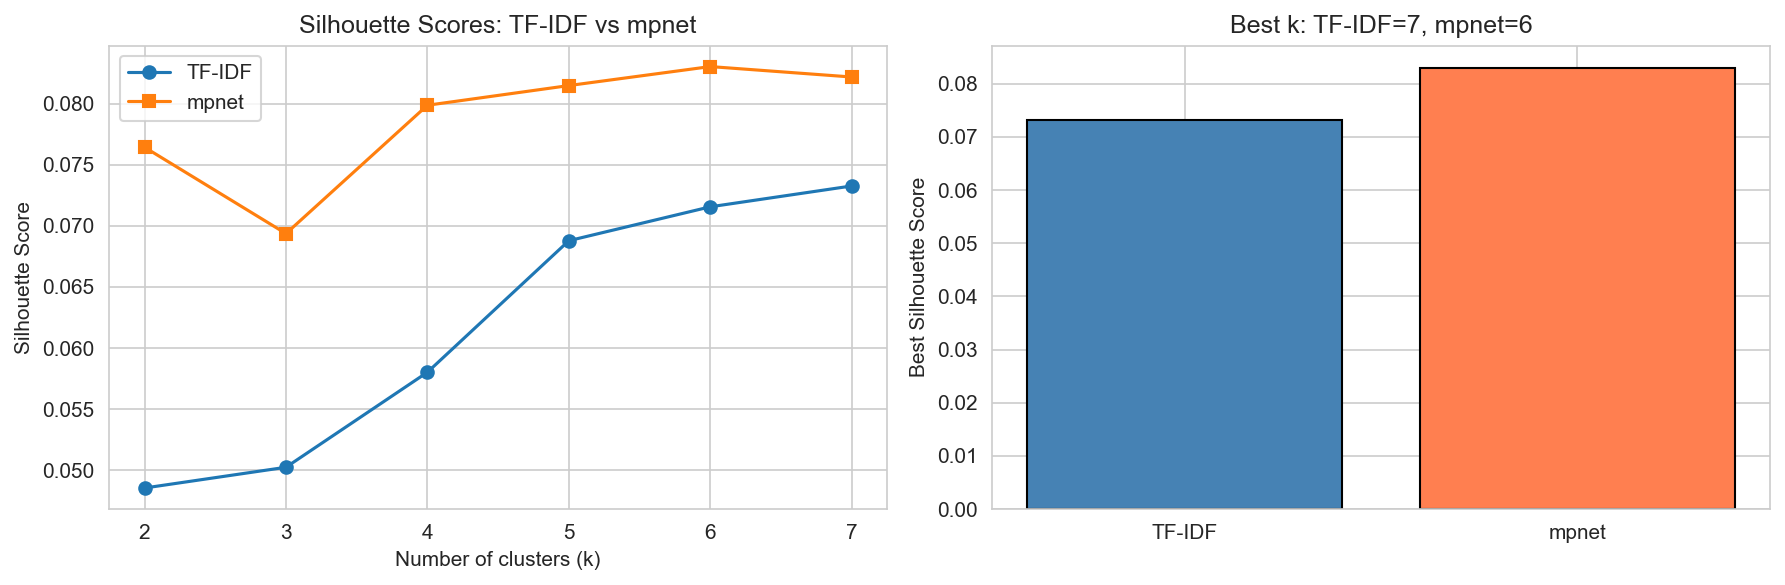

mpnet best k = 6, silhouette = 0.083


In [25]:
sil_scores_mpnet = {}
for k in range(2, 8):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_mpnet)
    sil_scores_mpnet[k] = silhouette_score(X_mpnet, labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(sil_scores.keys()), list(sil_scores.values()), 'o-', label='TF-IDF')
axes[0].plot(list(sil_scores_mpnet.keys()), list(sil_scores_mpnet.values()), 's-', label='mpnet')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Silhouette Score')
axes[0].set_title('Silhouette Scores: TF-IDF vs mpnet')
axes[0].legend()

best_k_mpnet = max(sil_scores_mpnet, key=sil_scores_mpnet.get)
axes[1].bar(['TF-IDF', 'mpnet'], [sil_scores[best_k], sil_scores_mpnet[best_k_mpnet]],
            color=['steelblue', 'coral'], edgecolor='black')
axes[1].set_ylabel('Best Silhouette Score')
axes[1].set_title(f'Best k: TF-IDF={best_k}, mpnet={best_k_mpnet}')

plt.tight_layout()
plt.savefig('silhouette_comparison.png', bbox_inches='tight')
plt.show()
print(f'mpnet best k = {best_k_mpnet}, silhouette = {sil_scores_mpnet[best_k_mpnet]:.3f}')

### B3. PCA scatter plot (mpnet clusters)

Same idea as the TF-IDF PCA plot — but now the 2D projection comes from 768-d mpnet embeddings. Bubble size is still funding.

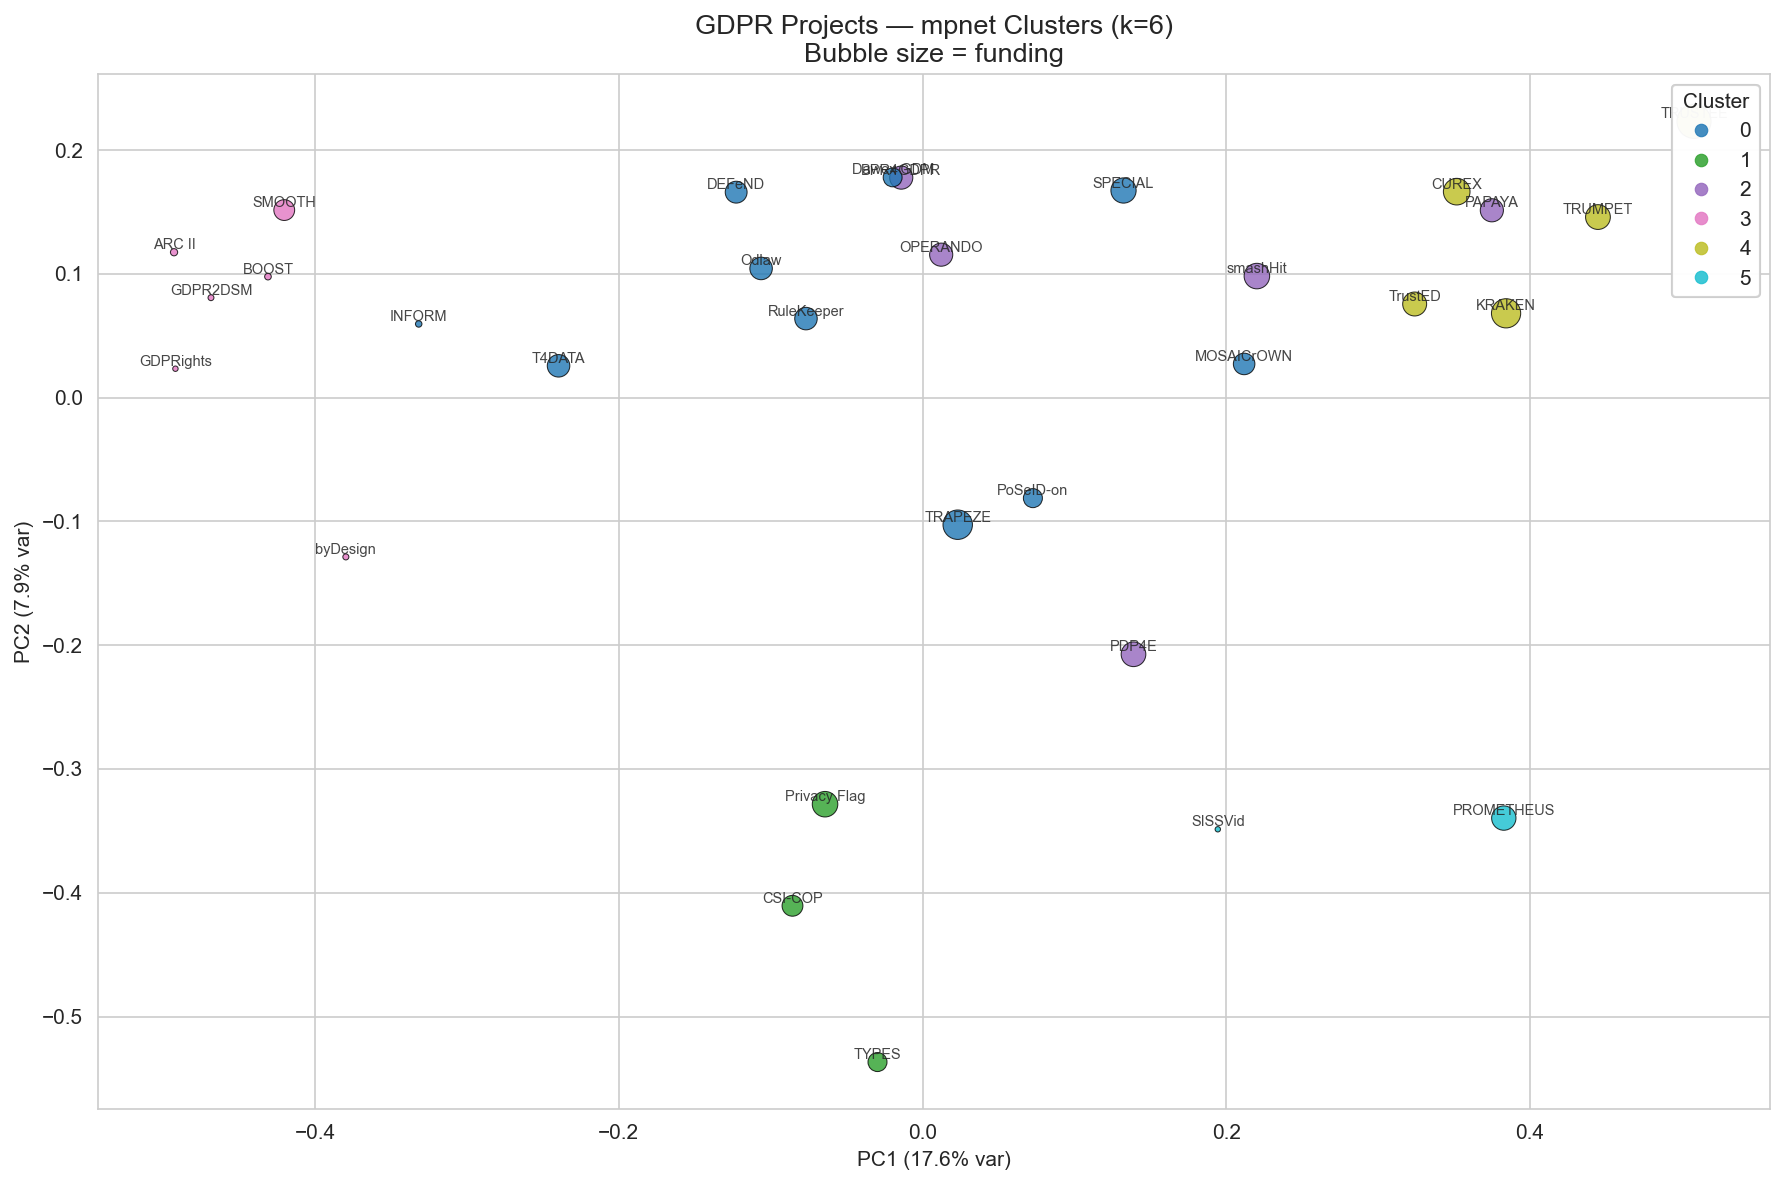

In [26]:
df['cluster_mpnet'] = AgglomerativeClustering(n_clusters=best_k_mpnet, linkage='ward').fit_predict(X_mpnet)

pca_mpnet = PCA(n_components=2)
coords_mpnet = pca_mpnet.fit_transform(X_mpnet)
df['pca_mpnet_x'] = coords_mpnet[:, 0]
df['pca_mpnet_y'] = coords_mpnet[:, 1]

fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(
    df['pca_mpnet_x'], df['pca_mpnet_y'],
    c=df['cluster_mpnet'],
    s=df['funding_eur'].fillna(df['funding_eur'].median()) / 30000,
    cmap='tab10',
    alpha=0.8,
    edgecolors='black',
    linewidth=0.5
)
for _, row in df.iterrows():
    ax.annotate(row['project_name'], (row['pca_mpnet_x'], row['pca_mpnet_y']),
                fontsize=7, ha='center', va='bottom', alpha=0.85)

ax.set_xlabel(f'PC1 ({pca_mpnet.explained_variance_ratio_[0]:.1%} var)')
ax.set_ylabel(f'PC2 ({pca_mpnet.explained_variance_ratio_[1]:.1%} var)')
ax.set_title(f'GDPR Projects — mpnet Clusters (k={best_k_mpnet})\nBubble size = funding', fontsize=13)
legend1 = ax.legend(*scatter.legend_elements(), title='Cluster', loc='upper right')
ax.add_artist(legend1)
plt.tight_layout()
plt.savefig('thematic_clusters_mpnet_pca.png', bbox_inches='tight')
plt.show()

### B4. mpnet cluster summary

In [27]:
for c in sorted(df['cluster_mpnet'].unique()):
    mask = df['cluster_mpnet'] == c
    cluster_projects = df.loc[mask, 'project_name'].tolist()
    cluster_funding = df.loc[mask, 'funding_eur'].dropna()
    cluster_domains = df.loc[mask, 'domain'].tolist()
    
    print(f'\n=== mpnet Cluster {c} ({mask.sum()} projects) ===')
    print(f'Projects: {", ".join(cluster_projects)}')
    print(f'Domains: {"; ".join(cluster_domains)}')
    if len(cluster_funding) > 0:
        print(f'Funding — mean: €{cluster_funding.mean():,.0f}, '
              f'median: €{cluster_funding.median():,.0f}, '
              f'range: €{cluster_funding.min():,.0f}–€{cluster_funding.max():,.0f}')
    else:
        print('Funding — no data')


=== mpnet Cluster 0 (10 projects) ===
Projects: Odlaw, RuleKeeper, SPECIAL, DEFeND, INFORM, PoSeID-on, TRAPEZE, MOSAICrOWN, T4DATA, Dawex GDM
Domains: Legacy Databases; Web Application Frameworks; Big Data, Semantic Web; Healthcare, Finance, Energy, Local Government; Education and Training; Government Services, Smart Cities; Telecom, Finance, Government; Data Marketplaces, Multi-party Analytics; Public Administration, Data Protection Authorities; Data Marketplaces, Data Sharing, Data Economy
Funding — mean: €3,164,286, median: €3,200,000, range: €290,000–€6,000,000

=== mpnet Cluster 1 (3 projects) ===
Projects: TYPES, CSI-COP, Privacy Flag
Domains: Online Advertising; Web and App Tracking, Citizen Science; Websites, Mobile Apps, IoT
Funding — mean: €3,333,333, median: €3,000,000, range: €2,500,000–€4,500,000

=== mpnet Cluster 2 (5 projects) ===
Projects: smashHit, PDP4E, BPR4GDPR, PAPAYA, OPERANDO
Domains: Connected Cars, Smart Cities; Software Engineering; Healthcare, Automotive, R

## Comparing TF-IDF vs mpnet

How much do the two methods agree? We use Adjusted Rand Index (ARI) — 1.0 means identical clusterings, 0 means no better than random. We also show a confusion matrix so you can see exactly which projects moved between clusters.

In [28]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix

# If best_k differs, re-cluster both at the same k for a fair comparison
compare_k = min(best_k, best_k_mpnet)
tfidf_labels = AgglomerativeClustering(n_clusters=compare_k, linkage='ward').fit_predict(X_dense)
mpnet_labels = AgglomerativeClustering(n_clusters=compare_k, linkage='ward').fit_predict(X_mpnet)

ari = adjusted_rand_score(tfidf_labels, mpnet_labels)
print(f'Adjusted Rand Index (at k={compare_k}): {ari:.3f}')
if ari > 0.5:
    print('Strong agreement — both methods find similar groupings.')
elif ari > 0.25:
    print('Moderate agreement — some overlap, but meaningful differences.')
else:
    print('Weak agreement — the two methods see different structure in the data.')

# Side-by-side comparison
comparison = df[['project_name']].copy()
comparison['tfidf_cluster'] = tfidf_labels
comparison['mpnet_cluster'] = mpnet_labels
comparison['same'] = comparison['tfidf_cluster'] == comparison['mpnet_cluster']
print(f'\nProjects in same cluster under both methods: {comparison["same"].sum()}/{len(comparison)}')
print(comparison.sort_values(['tfidf_cluster', 'mpnet_cluster']).to_string(index=False))

Adjusted Rand Index (at k=6): 0.067
Weak agreement — the two methods see different structure in the data.

Projects in same cluster under both methods: 4/31
project_name  tfidf_cluster  mpnet_cluster  same
     SPECIAL              0              0  True
     TRAPEZE              0              0  True
  MOSAICrOWN              0              0  True
       TYPES              0              1 False
      PAPAYA              0              2 False
     TRUSTEE              0              4 False
      KRAKEN              0              4 False
     TRUMPET              0              4 False
     TrustED              0              4 False
  PROMETHEUS              0              5 False
     SISSVid              0              5 False
      T4DATA              1              0 False
       PDP4E              1              2 False
    BPR4GDPR              1              2 False
    OPERANDO              1              2 False
       Odlaw              2              0 False
      INFO